<a href="https://colab.research.google.com/github/Ccperw/svd-image-compression/blob/main/notebooks/03_measuring_compression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
import os
import subprocess
import sys

USER = "Ccperw"
REPO = "svd-image-compression"

if os.path.exists(REPO):
  subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
  subprocess.run(
  ["git", "clone", f"https://github.com/{USER}/{REPO}.git", REPO],
  check=True)

sys.path.insert(0, f"{REPO}/src")
from compress import rank_k_approx
# checks if theres a variable for REPO already saved, and if there isn't,
# it runs a subprocess to clone the repo, then imports the compress src file
# to use the rank_k_approx function

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

A = data.camera().astype(float)
m, n = A.shape
T = data.text().astype(float)
print("Camera:", A.shape, "Text:", T.shape)
# imports a camera data type masked as a float
# sets m and n to the dimensions of A, respectively as rows and columns
# imports a text data type masked as a float
# prints out the dimensions of A and dimensions of T

Camera: (512, 512) Text: (172, 448)


In [28]:
def storage(m, n, k):
  # Number of values needed to store a rank-k approximation.
  return k * (m + n + 1)

def compression_ratio(m, n, k):
  # Original number of values divided by compressed number of values.
  return (m * n) / storage(m, n, k)

print("Original camera values:", m * n)
for k in [1, 10, 50, 100, 255, 256]:
  print(f"k={k:3d} stored={storage(m, n, k):6d}"
  f" ratio={compression_ratio(m, n, k):.2f}")
# calculates the number of data needed to store a full image by
# rows * columns * rank
# calculates the compression ratio by taking
# rows * columns / (rank * (rows + columns + 1))
# it then prints respective values of the data stored and compression ratio
# for each item in k

Original camera values: 262144
k=  1 stored=  1025 ratio=255.75
k= 10 stored= 10250 ratio=25.58
k= 50 stored= 51250 ratio=5.12
k=100 stored=102500 ratio=2.56
k=255 stored=261375 ratio=1.00
k=256 stored=262400 ratio=1.00


In [29]:
def rel_error(A, B):
  #Relative Frobenius error when B approximates A.
  return np.linalg.norm(A - B) / np.linalg.norm(A)
for k in [1, 5, 20, 50, 100]:
  Ak = rank_k_approx(A, k)
  print(f"k={k:3d} relative error={rel_error(A, Ak):.4f}")
# finds the norm of A-B and divides it by the norm of A to find the error between
# prints each value in k with its relative error calculated

k=  1 relative error=0.3604
k=  5 relative error=0.1720
k= 20 relative error=0.1012
k= 50 relative error=0.0636
k=100 relative error=0.0393


In [30]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)
def predicted_error(s, k):
  #Relative rank-k error computed from the singular values.
  return np.sqrt(np.sum(s[k:]**2) / np.sum(s**2))

for k in [1, 5, 20, 50, 100]:
  actual = rel_error(A, rank_k_approx(A, k))
  predicted = predicted_error(s, k)
  print(f"k={k:3d} actual={actual:.6f} predicted={predicted:.6f}")
# declares U, s, and Vt as the U, sigma, and vT parts of the SVD equation
# runs an error calculator that approximates using the singular values, 's'
# for each rank, 'k', the loop compares the error to the predicted error
# it outputs each term with print

k=  1 actual=0.360449 predicted=0.360449
k=  5 actual=0.172014 predicted=0.172014
k= 20 actual=0.101208 predicted=0.101208
k= 50 actual=0.063565 predicted=0.063565
k=100 actual=0.039329 predicted=0.039329


In [31]:
ks = np.arange(1, len(s) + 1)
errors = np.array([predicted_error(s, k) for k in ks])
for target in [0.10, 0.05, 0.02, 0.01]:
  k = ks[errors <= target][0]
  ratio = compression_ratio(m, n, k)
  print(f"k={k}, ratio={ratio:.2f}")
# ks includes all ranks from 1 to however many values are in 's'
# errors stores all predicted errors for each s, k and stores to an array
# the loop finds the smallest rank of each error limit at 10%, 5%, 2%, and 1%

k=21, ratio=12.18
k=73, ratio=3.50
k=186, ratio=1.38
k=263, ratio=0.97


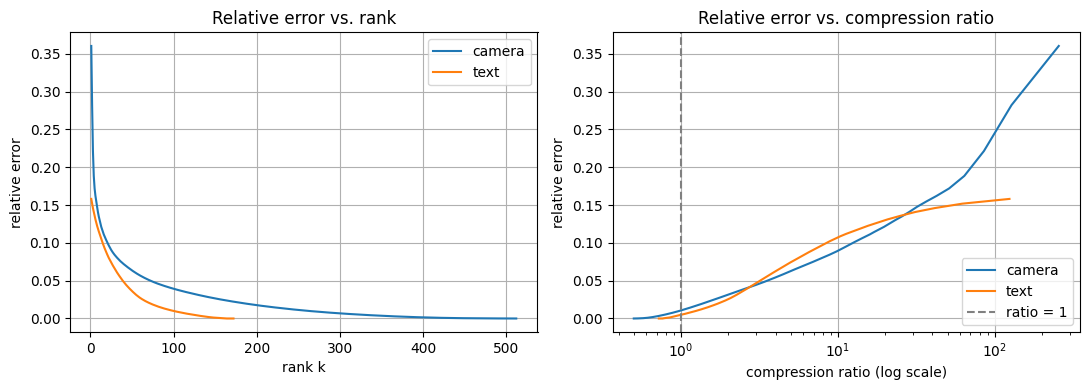

In [32]:
images = {"camera": A, "text": T}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for name, M in images.items():
  m_img, n_img = M.shape
  s_img = np.linalg.svd(M, compute_uv=False)
  ranks = np.arange(1, len(s_img) + 1)
  errs = [predicted_error(s_img, k) for k in ranks]
  ratios = [compression_ratio(m_img, n_img, k) for k in ranks]
  ax1.plot(ranks, errs, label=name)
  ax2.semilogx(ratios, errs, label=name)
ax1.set_title("Relative error vs. rank")
ax1.set_xlabel("rank k")
ax1.set_ylabel("relative error")
ax2.axvline(1, color="gray", linestyle="--", label="ratio = 1")
ax2.set_title("Relative error vs. compression ratio")
ax2.set_xlabel("compression ratio (log scale)")
ax2.set_ylabel("relative error")
for ax in (ax1, ax2):
  ax.grid()
  ax.legend()
plt.tight_layout()
plt.savefig("error_vs_ratio.png", dpi=150)
plt.show()
# stores camera image A and text image T using their names
# for each image, the loop takes its dimensions, single values, and finds the
# compression ratio and predicted error for each rank
# the left plot compares relative error and rank, while the right plot
# compares relative error and compression ratio on a logartihmic scale

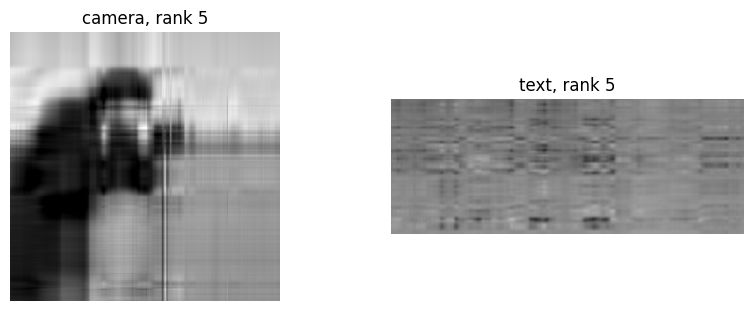

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (name, M) in zip(axes, images.items()):
  Mk = np.clip(rank_k_approx(M, 5), 0, 255)
  ax.imshow(Mk, cmap="gray", vmin=0, vmax=255)
  ax.set_title(f"{name}, rank 5")
  ax.axis("off")
plt.show()
# creates two plots next to eachother
# loop pairs each plot to an image name and matrix
# creates a rank 5 approximation
# np.clip keeps values between 0 and 255

In [36]:
A20 = rank_k_approx(A, 20)
outside = (A20 < 0) | (A20 > 255)
print("Out-of-range pixels:", outside.sum())
print("Fraction:", f"{outside.mean():.1%}")
print("Error before clipping:", round(rel_error(A, A20), 4))
print("Error after clipping:", round(rel_error(A, np.clip(A20, 0, 255)), 4))
# example of how clipping looks
# create approximation of a rank 20 matrix
# finds how many pixels are out of range
# finds error before and after clipping using previously built error calculator

Out-of-range pixels: 2634
Fraction: 1.0%
Error before clipping: 0.1012
Error after clipping: 0.1008


Saving sky.png to sky (5).png


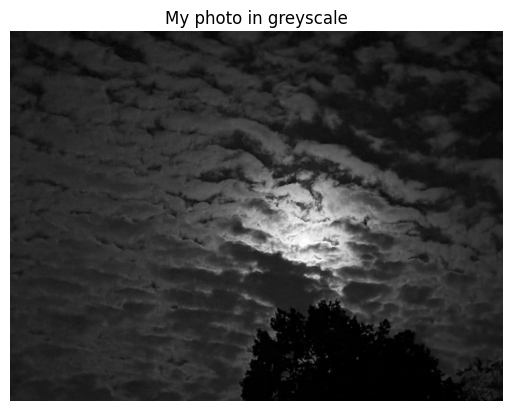

In [46]:
from google.colab import files
from PIL import Image
uploaded = files.upload()
# this code takes in an image uploaded by the user of the code

name = list(uploaded)[0]
img = Image.open(name).convert("L")
# this section takes the image and converts it to greyscale

img.thumbnail((800, 800))
P = np.array(img)
# this section compresses the image down to an 800x800 photo

plt.imshow(P, cmap="gray", vmin=0, vmax=255)
plt.title("My photo in greyscale")
plt.axis("off")
plt.show()
# this section plots the compressed, greyscaled version of the image

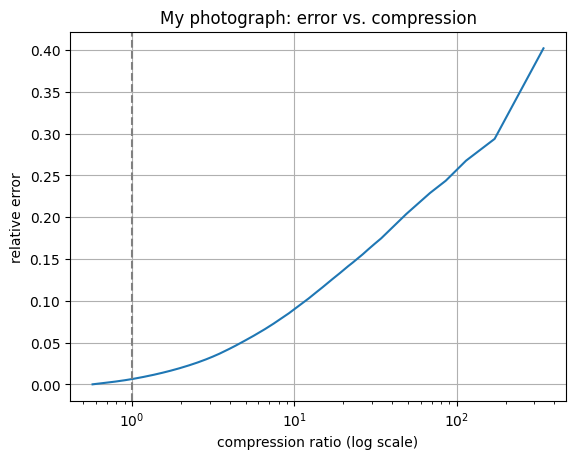

In [47]:
P_float = P.astype(float)
sp = np.linalg.svd(P_float, compute_uv=False)
kp = np.arange(1, len(sp) + 1)
ep = [predicted_error(sp, k) for k in kp]
mp, npix = P_float.shape
rp = [compression_ratio(mp, npix, k) for k in kp]
# creates values for s, k, e, m, n, and r for image P

plt.figure()
plt.semilogx(rp, ep)
plt.axvline(1, color="gray", linestyle="--")
plt.xlabel("compression ratio (log scale)")
plt.ylabel("relative error")
plt.title("My photograph: error vs. compression")
plt.grid()
plt.show()
# plots the comparison between error and compression

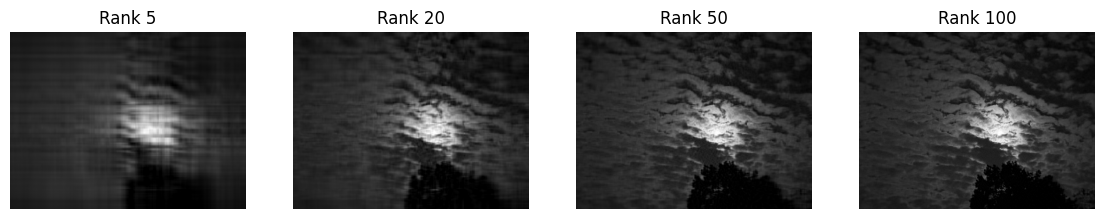

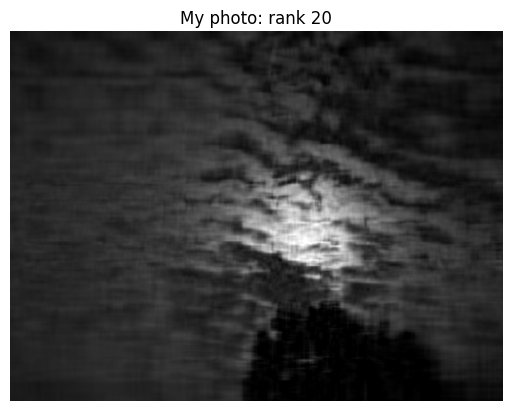

Chosen rank: 20
Relative error: 0.1258
Compression ratio: 17.13


In [48]:
# Compare approximations to choose a rank
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, k in zip(axes, [5, 20, 50, 100]):
    Pk = np.clip(rank_k_approx(P_float, k), 0, 255)
    ax.imshow(Pk, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Rank {k}")
    ax.axis("off")

plt.show()

# the rank I found was most balanced between readability and storage saving
k = 20

Pk = rank_k_approx(P_float, k)
error = predicted_error(sp, k)
ratio = compression_ratio(mp, npix, k)

plt.figure()
plt.imshow(np.clip(Pk, 0, 255), cmap="gray", vmin=0, vmax=255)
plt.title(f"My photo: rank {k}")
plt.axis("off")
plt.show()

print("Rank:", k)
print(f"Relative error: {error:.4f}")
print(f"Compression ratio: {ratio:.2f}")